In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [3]:
# 1. Load the dataset
df = pd.read_csv("CarPrice_Assignment.csv")

In [5]:
df

,car_ID,symboling,CarName,fueltype,aspiration,doornumber,carbody,drivewheel,enginelocation,wheelbase,...,enginesize,fuelsystem,boreratio,stroke,compressionratio,horsepower,peakrpm,citympg,highwaympg,price
0,1,3,alfa-romero giulia,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,13495.0
1,2,3,alfa-romero stelvio,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,16500.0
2,3,1,alfa-romero Quadrifoglio,gas,std,two,hatchback,rwd,front,94.5,...,152,mpfi,2.68,3.47,9.0,154,5000,19,26,16500.0
3,4,2,audi 100 ls,gas,std,four,sedan,fwd,front,99.8,...,109,mpfi,3.19,3.40,10.0,102,5500,24,30,13950.0
4,5,2,audi 100ls,gas,std,four,sedan,4wd,front,99.4,...,136,mpfi,3.19,3.40,8.0,115,5500,18,22,17450.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
200,201,-1,volvo 145e (sw),gas,std,four,sedan,rwd,front,109.1,...,141,mpfi,3.78,3.15,9.5,114,5400,23,28,16845.0
201,202,-1,volvo 144ea,gas,turbo,four,sedan,rwd,front,109.1,...,141,mpfi,3.78,3.15,8.7,160,5300,19,25,19045.0
202,203,-1,volvo 244dl,gas,std,four,sedan,rwd,front,109.1,...,173,mpfi,3.58,2.87,8.8,134,5500,18,23,21485.0
203,204,-1,volvo 246,diesel,turbo,four,sedan,rwd,front,109.1,...,145,idi,3.01,3.40,23.0,106,4800,26,27,22470.0


In [7]:
# 2. Clean column names and remove duplicates
df.columns = df.columns.str.strip().str.lower()
df = df.drop_duplicates()

In [9]:
# 3. Feature engineering: extract car brand
if "carname" in df.columns:
    df["brand"] = df["carname"].str.split().str[0]
    df = df.drop(columns=["carname"])

In [11]:
# 4. Select input features and target
target = "price"
X = df.drop(columns=[target])
y = df[target]

In [13]:
# 5. Identify numerical and categorical columns
num_cols = X.select_dtypes(include=np.number).columns.tolist()
cat_cols = X.select_dtypes(exclude=np.number).columns.tolist()

In [17]:
# 6. Preprocess the data
num_process = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

cat_process = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", num_process, num_cols),
    ("cat", cat_process, cat_cols)
])

In [19]:
# 7. Create the regression model
model = Pipeline([
    ("preprocessing", preprocessor),
    ("regressor", RandomForestRegressor(
        n_estimators=100, random_state=42
    ))
])

In [21]:
# 8. Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [23]:
# 9. Train the model
model.fit(X_train, y_train)
print("Model trained successfully!")

Model trained successfully!


In [25]:
# 10. Predict car prices
y_pred = model.predict(X_test)

In [27]:
# 11. Evaluate the model
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("Mean Absolute Error:", round(mae, 2))
print("Root Mean Squared Error:", round(rmse, 2))
print("R2 Score:", round(r2, 3))

Mean Absolute Error: 1320.72
Root Mean Squared Error: 1872.22
R2 Score: 0.956


In [29]:
# 12. Compare actual and predicted prices
results = pd.DataFrame({
    "Actual Price": y_test.values,
    "Predicted Price": np.round(y_pred, 2)
})

print("\nActual vs Predicted Prices:")
print(results.head())


Actual vs Predicted Prices:
   Actual Price  Predicted Price
0     30760.000         35448.32
1     17859.167         19540.77
2      9549.000          8976.17
3     11850.000         13107.14
4     28248.000         27086.93


Text(0.5, 1.0, 'Actual vs Predicted Car Prices')

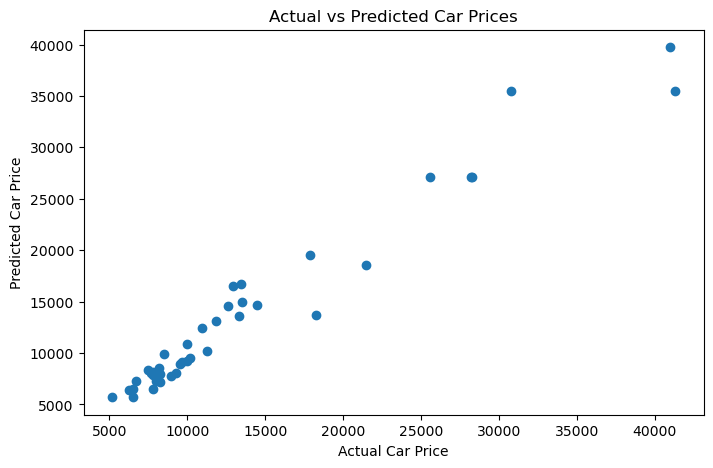

In [31]:
# 13. Visualize actual vs predicted prices
plt.figure(figsize=(8, 5))
plt.scatter(y_test, y_pred)
plt.xlabel("Actual Car Price")
plt.ylabel("Predicted Car Price")
plt.title("Actual vs Predicted Car Prices")

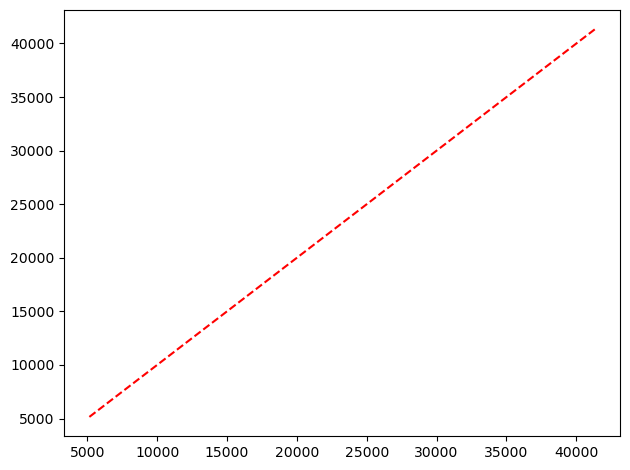

In [33]:
# Reference line
lower = min(y_test.min(), y_pred.min())
upper = max(y_test.max(), y_pred.max())
plt.plot([lower, upper], [lower, upper], "r--")

plt.tight_layout()
plt.show()